# Modelos ML | Modelo #5 - XGBoost

Este notebook estima a superfície de volatilidade implícita (IVS) usando a técnica de Machine Learning XGBoost.

Autor: Sérgio Sobral  
Data: 14/09/2025

Importação de Bibliotecas

In [85]:
import os
import json
import joblib
from datetime import datetime, timezone
import numpy as np
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, SplineTransformer
from sklearn.linear_model import RidgeCV
from sklearn.linear_model import LinearRegression
from typing import Optional, Sequence, Iterable, Tuple
from sklearn.base import BaseEstimator, TransformerMixin

from __future__ import annotations

from sklearn.ensemble import RandomForestRegressor

Designações Centrais e Caminhos

In [86]:
# Designações Centrais e Caminhos
DIR_TRATADOS = "02. Dados/02. Dados Tratados/"
DIR_RESULTADOS = "04. Resultados/05. Modelo #5 - XGBoost/"
DIR_GRAFICOS = "03. Output/01. Gráficos/08. Modelo #5 - XGBoost/"
DIR_TABELAS = "03. Output/02. Tabelas/05. Modelo #5 - XGBoost/"

# Criar diretório de gráficos/tabelas/resultados se não existir
os.makedirs(DIR_GRAFICOS, exist_ok=True)
os.makedirs(DIR_RESULTADOS, exist_ok=True)
os.makedirs(DIR_TABELAS, exist_ok=True)

# Ficheiros de input
ficheiro_universo        = os.path.join(DIR_TRATADOS, "Universo_Modelizacao_v1.00.parquet")
ficheiro_inner_train     = os.path.join(DIR_TRATADOS, "df_inner_train.parquet")
ficheiro_inner_tunning   = os.path.join(DIR_TRATADOS, "df_inner_tunning.parquet")
ficheiro_train_full      = os.path.join(DIR_TRATADOS, "df_train_full.parquet")
ficheiro_test_puro       = os.path.join(DIR_TRATADOS, "df_test_puro.parquet")

# Config
# FEATURES = ("log_moneyness", "T", "risk_free_rate", "option_is_call")
FEATURES = ("log_moneyness", "T", "option_is_call")
TARGET   = "iv_teorica"
PRED_COL = "ivs_modelo"


# Save Models (nomes finais)
MODEL_PATH_INNER = os.path.join(DIR_RESULTADOS, "05. XGBoost_model_inner.joblib")
META_PATH_INNER  = os.path.join(DIR_RESULTADOS, "05. XGBoost_model_inner.meta.json")

BEST_PARAMS = os.path.join(DIR_RESULTADOS, "05. XGBoost_best_params.json")
LINEAR_ADJUST = os.path.join(DIR_RESULTADOS, "05. XGBoost_linear_adjust.json")

MODEL_PATH_FINAL = os.path.join(DIR_RESULTADOS, "05. XGBoost_model.joblib")
META_PATH_FINAL  = os.path.join(DIR_RESULTADOS, "05. XGBoost_model.meta.json")

Funções Auxiliares

Palete de Cores:
azul1: #11469b
azul2: #2063c0
azul3: #5a90e7
cinza1: #777777
cinza2: #AAAAAA
cinza3: #bbbbbb
preto: #000000
branco: #ffffff

Estilos de Linha:
contínua: -
tracejada: --
ponto-traço: -.
pontilhada: :
contínua2: -
tracejada2: --
ponto-traço2: -.
pontilhada2: :


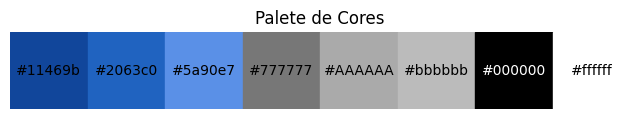

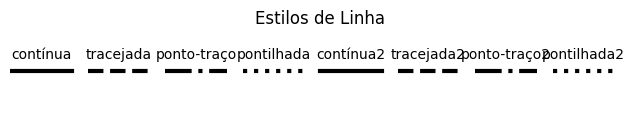

In [87]:
%run "01. Notebooks/00. Configuração/02_Ficheiro Auxiliar.ipynb"

# Visualizar paleta de cores e estilos de linha carregados
if 'mostrar_cores' in globals() and 'PALETA_CORES' in globals():
    mostrar_cores(PALETA_CORES)
if 'mostrar_estilos' in globals() and 'ESTILOS_LINHA' in globals():
    mostrar_estilos(ESTILOS_LINHA)

Carregamento dos Dados

In [88]:
# Carregamento do ficheiro parquet
df_inner_train = pd.read_parquet(ficheiro_inner_train)
df_inner_tunning = pd.read_parquet(ficheiro_inner_tunning)
df_train_full = pd.read_parquet(ficheiro_train_full)
df_test_puro = pd.read_parquet(ficheiro_test_puro)

# Verificação inicial
(df_inner_train.shape, df_inner_tunning.shape, df_train_full.shape, df_test_puro.shape)

((5970843, 11), (1534395, 11), (7505238, 11), (1292514, 11))

Modelização | Setup Inicial

In [89]:
# 1) Checks básicos
def _basic_checks(df, features, target):
    cols = list(features) + [target]
    em_falta = [c for c in cols if c not in df.columns]
    if em_falta: raise ValueError(f"Colunas em falta: {em_falta}")

    sub = df[cols]
    nan_counts = sub.isna().sum()
    if nan_counts.any():
        raise ValueError(f"Há NaN nas colunas usadas: {nan_counts[nan_counts>0].to_dict()}")

    inf_detalhe = {}
    for c in cols:
        v = sub[c].to_numpy()
        if not np.isfinite(v).all():
            inf_detalhe[c] = int(np.isinf(v).sum()) + int(np.isnan(v).sum())
    if inf_detalhe:
        raise ValueError(f"Valores não finitos detectados: {inf_detalhe}")
    return sub



# ---------------------------------------------------------------------
# 2) Utilidades de dtype e sampling (RAM‑safe)
def _prepare_xy(df: pd.DataFrame, features: Iterable[str], target: str):
    # Cast eficiente para poupar RAM
    df2 = df.copy()
    for c in features:
        if c == "option_is_call":
            df2[c] = df2[c].astype("int8")
        else:
            df2[c] = df2[c].astype("float32")

    X = df2[list(features)].values 
    y = df2[target].astype("float32").values  
    return X, y

def _make_bins(df: pd.DataFrame, lm_col="log_moneyness", t_col="T", n_lm=30, n_t=12):
    lm_bins = np.linspace(df[lm_col].min(), df[lm_col].max(), n_lm+1)
    t_bins  = np.linspace(df[t_col].min(),  df[t_col].max(),  n_t+1)
    return lm_bins, t_bins

def balanced_sample(df, max_per_bin=5000, lm_col="log_moneyness", t_col="T"):
    df = df.copy()
    lm_q = np.quantile(df[lm_col].values, np.linspace(0, 1, 31))
    t_q  = np.quantile(df[t_col].values,  np.linspace(0, 1, 13))
    lm_edges = np.unique(lm_q)
    t_edges  = np.unique(t_q)
    if lm_edges.size < 3:
        lm_edges = np.linspace(df[lm_col].min(), df[lm_col].max(), 31)
    if t_edges.size < 3:
        t_edges  = np.linspace(df[t_col].min(),  df[t_col].max(),  13)

    lm_cat = pd.cut(df[lm_col], bins=lm_edges, include_lowest=True, right=False)
    t_cat  = pd.cut(df[t_col],  bins=t_edges,  include_lowest=True, right=False)
    df["_lm_bin"] = lm_cat.cat.codes
    df["_t_bin"]  = t_cat.cat.codes

    out = (df.loc[(df["_lm_bin"]>=0) & (df["_t_bin"]>=0)]
             .groupby(["_lm_bin","_t_bin"], group_keys=False)
             .apply(lambda g: g.sample(min(len(g), max_per_bin), random_state=42))
             .drop(columns=["_lm_bin","_t_bin"]))
    return out



# ---------------------------------------------------------------------
# ======================================
# 05 — XGBoost (modelo #5)
# ======================================

from __future__ import annotations
import os, json, joblib, numpy as np, pandas as pd
from typing import Iterable, Tuple
from datetime import datetime, timezone

from xgboost import XGBRegressor
from sklearn.inspection import permutation_importance

# ---------------------------------------------------------------------
# 3) Construção do modelo base (GPU/CPU)
def build_xgb(params: dict | None = None, use_gpu: bool = True) -> XGBRegressor:
    base = dict(
        objective="reg:squarederror",
        eval_metric="rmse",
        n_estimators=2000,
        learning_rate=0.05,
        max_depth=6,
        min_child_weight=5,
        gamma=0.1,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=1.0,
        reg_alpha=0.0,
        random_state=42,
        n_jobs=-1,
        tree_method="hist",                 # <- SEMPRE 'hist'
        device=("cuda" if use_gpu else "cpu"),  # <- e aqui escolhes GPU/CPU
    )
    if params:
        base.update(params)
        if "tree_method" in base and base["tree_method"] != "hist":
            base["tree_method"] = "hist"
    return XGBRegressor(**base)


# ---------------------------------------------------------------------
# 4) Tuning (random search simples + early stopping)
def _rmse(y_true: np.ndarray, y_pred: np.ndarray) -> float:
    diff = (y_true - y_pred).astype("float64")
    return float(np.sqrt(np.mean(diff * diff)))

def sample_param_space(n_samples: int, rng: int = 42) -> list[dict]:
    import random
    rnd = random.Random(rng)
    
    # run 1
    # n_choices = [400, 800, 1200, 1600, 2000]

    # run 2: mais focado (em torno do best anterior)
    # n_choices = [400, 800, 1200, 1600, 2000, 2400]

    # run 3: mais focado ainda
    n_choices = [1600, 2000, 2400, 3000]

    # run 4: (ainda mais focado)
    # n_choices = [1600, 1800, 2000, 2200, 2400, 2600]

    out = []
    for _ in range(n_samples):
        cfg = {
            # run 1
            # "max_depth":        rnd.choice([4,5,6,7,8,9,10]),
            # "min_child_weight": rnd.choice([1,2,3,5,7,10]),
            # "gamma":            rnd.uniform(0.0, 0.5),
            # "subsample":        rnd.uniform(0.6, 1.0),
            # "colsample_bytree": rnd.uniform(0.6, 1.0),
            # "learning_rate":    rnd.uniform(0.01, 0.15),
            # "reg_lambda":       rnd.uniform(0.0, 5.0),
            # "reg_alpha":        rnd.uniform(0.0, 2.0),
            # "n_estimators":     rnd.choice(n_choices),  # <- agora afinamos também isto

            # run 2: mais focado (em torno do best anterior)
            # capacidade contida (o best foi depth=4)
            # "max_depth":        rnd.choice([4, 5, 6]),
            # "min_child_weight": rnd.choice([2, 3, 5, 7]),
            # # splits mais conservadores
            # "gamma":            rnd.uniform(0.00, 0.20),
            # # estocasticidade (ligeiramente acima do best)
            # "subsample":        rnd.uniform(0.70, 1.00),
            # "colsample_bytree": rnd.uniform(0.70, 1.00),
            # # LR mais baixo (compensado por mais árvores)
            # "learning_rate":    rnd.uniform(0.020, 0.060),
            # "reg_lambda":       rnd.uniform(0.50, 2.50),
            # "reg_alpha":        rnd.uniform(0.00, 0.50),
            # "n_estimators":     rnd.choice(n_choices),

            # run 3: (mais focado ainda)
            "max_depth":        rnd.choice([3, 4, 5]),
            "min_child_weight": rnd.choice([5, 7, 9, 11]),
            "gamma":            rnd.uniform(0.05, 0.30),
            "subsample":        rnd.uniform(0.65, 0.85),
            "colsample_bytree": rnd.uniform(0.65, 0.85),
            "learning_rate":    rnd.uniform(0.020, 0.040),
            "reg_lambda":       rnd.uniform(1.0, 6.0),
            "reg_alpha":        rnd.uniform(0.10, 0.90),
            "n_estimators":     rnd.choice(n_choices),

            # run 4: (ainda mais focado)
            # "max_depth":        rnd.choice([4, 5, 6]),
            # "min_child_weight": rnd.choice([5, 7, 9, 11]),
            # "gamma":            rnd.uniform(0.03, 0.15),
            # "subsample":        rnd.uniform(0.62, 0.82),
            # "colsample_bytree": rnd.uniform(0.62, 0.82),
            # "learning_rate":    rnd.uniform(0.022, 0.045),
            # "reg_lambda":       rnd.uniform(1.5, 6.5),
            # "reg_alpha":        rnd.uniform(0.20, 1.10),
            # "n_estimators":     rnd.choice(n_choices),

        }
        out.append(cfg)
    return out

def tune_xgb(
    df_inner_train: pd.DataFrame,
    df_inner_tunning: pd.DataFrame,
    features: Iterable[str],
    target: str,
    n_iter: int = 40,
    use_balanced_sample: bool = True,
    max_per_bin: int = 5000,
    random_state: int = 42,
    use_gpu: bool = True,
    pred_col: str = "ivs_modelo",
) -> tuple[dict, int, pd.DataFrame, pd.DataFrame]:
    """
    Random search SEM early stopping:
      - treino: amostra balanceada de inner_train (ou o próprio inner_train)
      - validação: inner_tunning
    Retorna: (best_params, best_iteration (== n_estimators-1), df_inner_train_pred, df_inner_tunning_pred)
    """
    _basic_checks(df_inner_train, features, target)
    _basic_checks(df_inner_tunning, features, target)

    # amostra balanceada para acelerar busca
    train_df = balanced_sample(df_inner_train, max_per_bin=max_per_bin) if use_balanced_sample else df_inner_train

    X_tr_s, y_tr_s = _prepare_xy(train_df,        features, target)
    X_in,  y_in    = _prepare_xy(df_inner_train,  features, target)
    X_va,  y_va    = _prepare_xy(df_inner_tunning,features, target)

    base_params = dict(objective="reg:squarederror", eval_metric="rmse")
    cand_list = sample_param_space(n_iter, rng=random_state)

    best = dict(params=None, best_rmse=np.inf, model=None)
    for i, cand in enumerate(cand_list, 1):
        # evitar paralelismo aninhado
        params_i = {**base_params, **cand, "n_jobs": 1}
        # constrói modelo (GPU/CPU conforme flag)
        model_i = build_xgb(params=params_i, use_gpu=use_gpu)
        model_i.fit(X_tr_s, y_tr_s, verbose=False)

        # avalia na validação
        y_va_hat = model_i.predict(X_va).astype("float32")
        y_va_hat = np.clip(y_va_hat, 1e-4, 2.0)
        rmse_va = _rmse(y_va, y_va_hat)

        if rmse_va < best["best_rmse"]:
            best.update(params=params_i, best_rmse=rmse_va, model=model_i)

    # melhores parâmetros (limpa n_jobs=1 para treino final)
    best_params = dict(best["params"])
    best_params["n_jobs"] = -1

    # definimos "best_iteration" para manter compatibilidade com o teu fluxo
    best_iteration = int(best_params.get("n_estimators", 1)) - 1

    # Refit no inner_train completo com os melhores parâmetros
    best_refit = build_xgb(best_params, use_gpu=use_gpu)
    best_refit.fit(X_in, y_in, verbose=False)

    # Previsões (clip apenas nas previsões)
    y_hat_in = np.clip(best_refit.predict(X_in).astype("float32"), 1e-4, 2.0)
    y_hat_va = np.clip(best_refit.predict(X_va).astype("float32"), 1e-4, 2.0)

    df_inner_train_pred   = df_inner_train.copy()
    df_inner_tunning_pred = df_inner_tunning.copy()
    df_inner_train_pred[pred_col]   = y_hat_in
    df_inner_tunning_pred[pred_col] = y_hat_va

    return best_params, best_iteration, df_inner_train_pred, df_inner_tunning_pred



# ---------------------------------------------------------------------
# 5) Treino final
def train_xgb(
    df_train_full: pd.DataFrame,
    features: Iterable[str],
    target: str,
    best_params: dict | None = None,
    best_iteration: int | None = None,
    use_gpu: bool = True,
    return_in_sample_pred: bool = True,
    pred_col: str = "ivs_modelo",
) -> tuple[XGBRegressor, dict, pd.DataFrame | None]:
    """
    Treina XGBRegressor em train_full.
    - Se best_iteration for fornecido: define n_estimators = best_iteration (+1 por segurança).
    - Se não houver best_params: usa defaults robustos.
    """
    _basic_checks(df_train_full, features, target)
    X_tr, y_tr = _prepare_xy(df_train_full, features, target)

    params = dict(best_params) if best_params else {}
    if best_iteration is not None:
        params["n_estimators"] = int(best_iteration) + 1
        # margem opcional de +10%:
        params["n_estimators"] = int(max(params["n_estimators"], round((best_iteration + 1) * 1.10)))

    xgb = build_xgb(params, use_gpu=use_gpu)
    xgb.fit(X_tr, y_tr, verbose=False)

    meta = {
        "model_type": "XGBRegressor",
        "features": list(features),
        "target": target,
        "n_obs": int(X_tr.shape[0]),
        "params": xgb.get_params(),
        "trained_at": datetime.now(timezone.utc).isoformat() + "Z",
        "date_min": str(df_train_full["quote_date"].min()) if "quote_date" in df_train_full.columns else None,
        "date_max": str(df_train_full["quote_date"].max()) if "quote_date" in df_train_full.columns else None,
        "best_iteration": int(best_iteration) if best_iteration is not None else None,
    }

    df_train_pred = None
    if return_in_sample_pred:
        y_hat_tr = xgb.predict(X_tr).astype("float32")
        y_hat_tr = np.clip(y_hat_tr, 1e-4, 2.0)
        df_train_pred = df_train_full.copy()
        df_train_pred[pred_col] = y_hat_tr

    return xgb, meta, df_train_pred


# ---------------------------------------------------------------------
# 6) Aplicação do modelo
def apply_xgb_model(
    df: pd.DataFrame,
    model: XGBRegressor,
    features: Iterable[str],
    pred_col: str = "ivs_modelo",
    clip_pred: bool = True,
    clip_min: float = 1e-4,
    clip_max: float = 2.0,
) -> pd.DataFrame:
    faltam = [c for c in features if c not in df.columns]
    if faltam:
        raise ValueError(f"Colunas em falta: {faltam}")
    X, _ = _prepare_xy(df.assign(__y=0.0), features, "__y")
    y_hat = model.predict(X).astype("float32")
    if clip_pred:
        y_hat = np.clip(y_hat, clip_min, clip_max)
    out = df.copy()
    out[pred_col] = y_hat
    return out


# ---------------------------------------------------------------------
# 7) Importâncias
def xgb_importances(
    model: XGBRegressor,
    df_ref: pd.DataFrame,
    features: Iterable[str],
    target: str,
    n_repeats: int = 5,
    max_rows: int | None = 200_000,   # <- novo
) -> pd.DataFrame:
    feats = list(features)

    booster = model.get_booster()
    gain_map = booster.get_score(importance_type="gain")
    gain_vals = [gain_map.get(f"f{i}", 0.0) for i in range(len(feats))]

    # Amostra para permutation (acelera muito em datasets enormes)
    ref = df_ref
    if (max_rows is not None) and (len(ref) > max_rows):
        ref = ref.sample(max_rows, random_state=42)

    X_ref, y_ref = _prepare_xy(ref, feats, target)
    perm = permutation_importance(model, X_ref, y_ref, n_repeats=n_repeats, random_state=42, n_jobs=-1)

    df_imp = pd.DataFrame({
        "feature": feats,
        "gain_importance": gain_vals,
        "permutation_importance": perm.importances_mean,
        "permutation_std": perm.importances_std,
    }).sort_values(["permutation_importance", "gain_importance"], ascending=False).reset_index(drop=True)

    return df_imp



# ---------------------------------------------------------------------
# 8) Conveniências de IO para parâmetros ótimos (usando os teus paths)
def save_best_params(best_params: dict, best_iteration: int | None, best_path: str):
    payload = dict(best_params=best_params, best_iteration=best_iteration)
    with open(best_path, "w", encoding="utf-8") as f:
        json.dump(payload, f, ensure_ascii=False, indent=2)

def load_best_params(best_path: str) -> tuple[dict | None, int | None]:
    if not os.path.exists(best_path):
        return None, None
    with open(best_path, "r", encoding="utf-8") as f:
        d = json.load(f)
    return d.get("best_params"), d.get("best_iteration")



# ---------------------------------------------------------------------
# 9) Guardar / carregar modelo
def save_model(model, meta: dict, model_path: str, meta_path: str):
    """Guarda o pipeline treinado (joblib) e o dicionário meta (JSON) nos caminhos indicados."""
    joblib.dump(model, model_path)
    with open(meta_path, "w", encoding="utf-8") as f:
        json.dump(meta, f, ensure_ascii=False, indent=2)

def load_model(model_path: str, meta_path: str):
    """Carrega o pipeline treinado e o meta JSON a partir dos caminhos indicados; devolve (model, meta)."""
    model = joblib.load(model_path)
    meta = None
    if os.path.exists(meta_path):
        with open(meta_path, "r", encoding="utf-8") as f:
            meta = json.load(f)
    return model, meta

Modelização | Tuning (inner_tunning)

In [90]:
# --- 1) TUNING em inner (random search; sem ES) ---
best_params, best_it, df_inner_train_pred, df_inner_tunning_pred = tune_xgb(
    df_inner_train, df_inner_tunning,
    FEATURES, TARGET,
    n_iter=150,                 # ajusta se quiseres mais/menos busca
    use_balanced_sample=True,  # usa amostra por bins para acelerar
    max_per_bin=5000,
    use_gpu=True,
    pred_col=PRED_COL
)

print("Melhores parâmetros:", best_params)
print("best_it (≈ n_estimators-1):", best_it)

# (Opcional) guardar melhores parâmetros para reuso/reprodutibilidade
save_best_params(best_params, best_it, BEST_PARAMS)

C:\Users\sergi\AppData\Local\Temp\ipykernel_8260\1098961180.py:61: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.sample(min(len(g), max_per_bin), random_state=42))


Melhores parâmetros: {'objective': 'reg:squarederror', 'eval_metric': 'rmse', 'max_depth': 5, 'min_child_weight': 5, 'gamma': 0.05625268880566674, 'subsample': 0.7050058636738239, 'colsample_bytree': 0.6946421476297646, 'learning_rate': 0.03472942428328025, 'reg_lambda': 4.383497437114556, 'reg_alpha': 0.8137436541638764, 'n_estimators': 1600, 'n_jobs': -1}
best_it (≈ n_estimators-1): 1599


Ajuste linear para correção de nível

In [91]:
# # --- Calibração linear em inner_tunning: y ≈ a + b * yhat ---
# X_cal = df_inner_tunning_pred[[PRED_COL]].values
# y_cal = df_inner_tunning_pred[TARGET].values

# lin = LinearRegression().fit(X_cal, y_cal)
# a = float(lin.intercept_)
# b = float(lin.coef_[0])

# print(f"Calibração (inner_tunning): y ≈ {a:.6f} + {b:.6f} * yhat")

# # Guardar parâmetros da calibração
# os.makedirs(os.path.dirname(LINEAR_ADJUST), exist_ok=True)
# with open(LINEAR_ADJUST, "w", encoding="utf-8") as f:
#     json.dump({
#         "type": "linear",
#         "a": a,
#         "b": b,
#         "fitted_on": "inner_tunning",
#         "n_obs": int(len(df_inner_tunning_pred))
#     }, f, ensure_ascii=False, indent=2)
# print(f"✔️ Parâmetros de calibração guardados em {LINEAR_ADJUST}")

Modelização | Refit best params e calibração sobre inner_training e inner_tunning

In [92]:
# (Opcional) guardar um modelo “inner_refit” (útil para auditoria)
xgb_inner, meta_inner, _ = train_xgb(
    df_inner_train, FEATURES, TARGET,
    best_params=best_params,
    best_iteration=best_it,
    use_gpu=True,
    return_in_sample_pred=False,
    pred_col=PRED_COL
)
save_model(xgb_inner, meta_inner, MODEL_PATH_INNER, META_PATH_INNER)

Modelização | Training Final (train_full)

In [93]:
# --- 2) Treino final em train_full com best params/iter ---
xgb_final, meta_final, df_train_full_pred = train_xgb(
    df_train_full, FEATURES, TARGET,
    best_params=best_params,
    best_iteration=best_it,
    use_gpu=True,
    return_in_sample_pred=True,   # para obter df_train_full_pred
    pred_col=PRED_COL
)
save_model(xgb_final, meta_final, MODEL_PATH_FINAL, META_PATH_FINAL)

Modelização | Teste (test_puro)

In [94]:
# --- 3) Aplicar ao test_puro (e a qualquer outro split) ---
df_test_puro_pred = apply_xgb_model(
    df_test_puro, xgb_final, FEATURES,
    pred_col=PRED_COL,
    clip_pred=True
)

print("✔️ ivs_modelo criado em test_puro.")

✔️ ivs_modelo criado em test_puro.


Modelização | Iiner_tunning e test_puro com calibração linear (regime financeiro)

In [95]:
# # 0) Sanity checks
# assert PRED_COL in df_inner_tunning_pred.columns, "PRED_COL não existe em df_inner_tunning_pred"
# assert PRED_COL in df_test_puro_pred.columns,  "PRED_COL não existe em df_test_puro_pred"

# # 1) Carregar (a,b) do ajuste linear feito em inner_tunning
# with open(LINEAR_ADJUST, "r", encoding="utf-8") as f:
#     cal = json.load(f)
# a, b = float(cal["a"]), float(cal["b"])
# print(f"[Calib] y ≈ {a:.6f} + {b:.6f} * yhat  (fit_on={cal.get('fitted_on')}, n_obs={cal.get('n_obs')})")

# # 2) Função que retorna um DF **novo** (cópia) com calibração aplicada
# def apply_calibration_copy(df: pd.DataFrame, pred_col: str, a: float, b: float, clip: bool = True) -> pd.DataFrame:
#     out = df.copy()
#     raw_col = f"{pred_col}_raw"
#     if raw_col not in out.columns:
#         out[raw_col] = out[pred_col].astype("float32")
#     ycal = a + b * out[pred_col].to_numpy(dtype=np.float32)
#     if clip:
#         ycal = np.clip(ycal, 1e-4, 2.0)
#     out[pred_col] = ycal.astype("float32")
#     return out

# # 3) Criar DFs calibrados (originais permanecem intactos para comparação)
# df_inner_tunning_pred_cal = apply_calibration_copy(df_inner_tunning_pred, PRED_COL, a, b, clip=True)
# df_test_puro_pred_cal   = apply_calibration_copy(df_test_puro_pred,   PRED_COL, a, b, clip=True)

# print("✔️ DFs calibrados criados: 'df_inner_tunning_pred_cal' e 'df_test_puro_pred_cal'.")
# print("   (Originals preservados: 'df_inner_tunning_pred' e 'df_test_puro_pred')")

Importância dos Features

In [96]:
# -------------------------------------------------------------
# IMPORTÂNCIAS XGBOOST (GAIN + PERMUTATION)
# -------------------------------------------------------------

# Recalcular importâncias com base no modelo treinado
df_import = xgb_importances(
    model=xgb_final,
    df_ref=df_test_puro,
    features=FEATURES,
    target=TARGET,
    n_repeats=5,
    max_rows=200_000  # acelera sem perda substancial de robustez
)

# Visualização rápida
display(df_import)

,feature,gain_importance,permutation_importance,permutation_std
0,log_moneyness,174.250320,2.911528,0.023323
1,T,40.940235,0.741268,0.004049
2,option_is_call,84.340256,0.207360,0.001748


Métricas de Avaliação

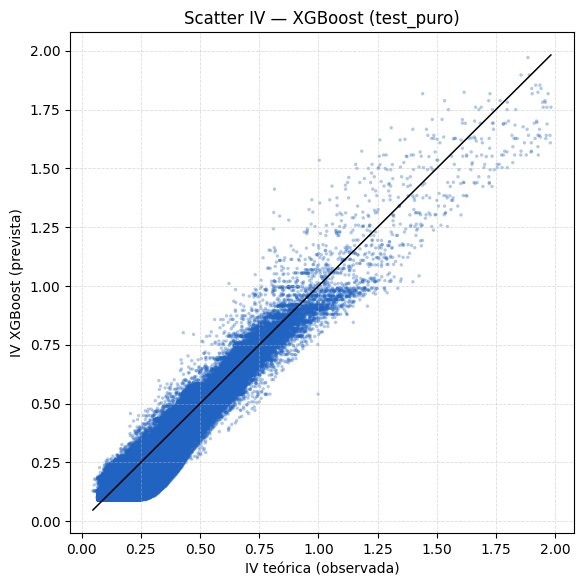

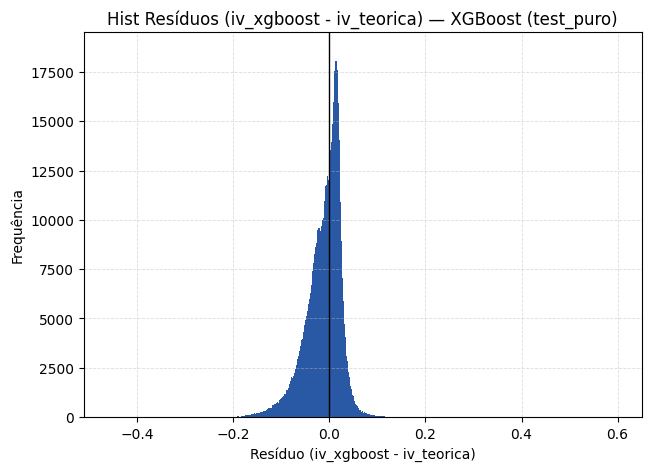

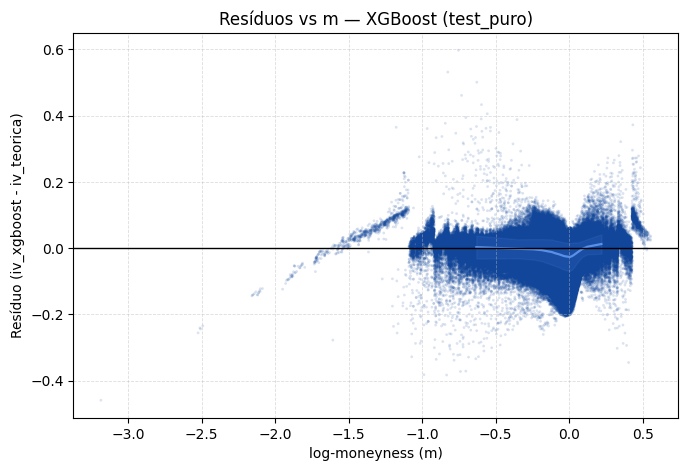

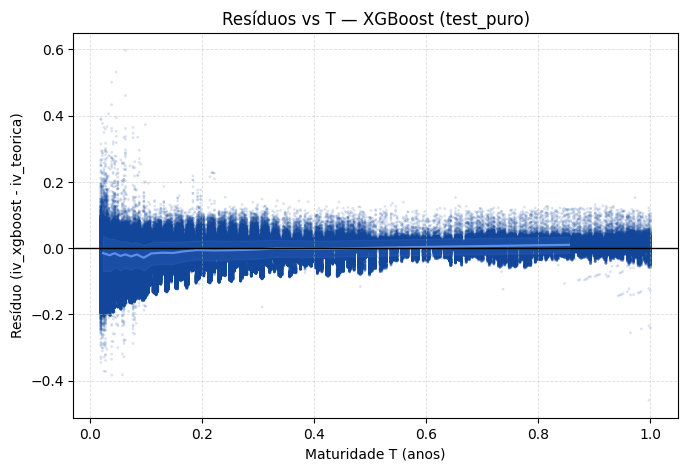

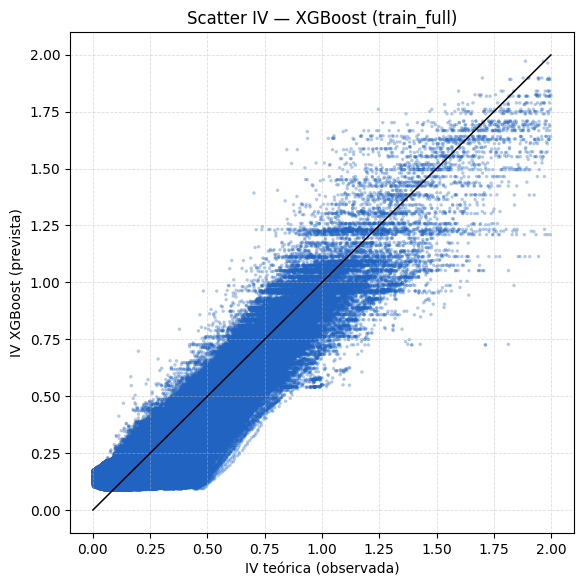

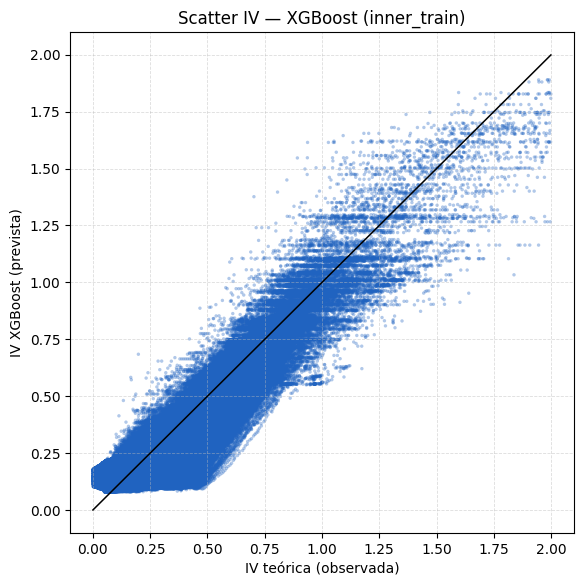

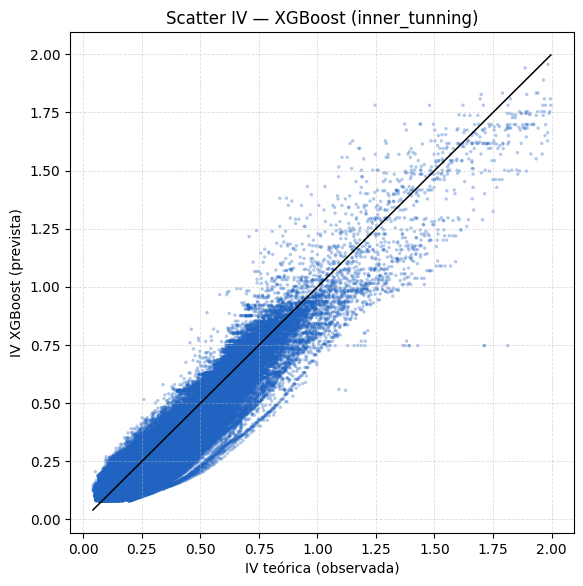

,model,split,analysis,variant,n_obs,RMSE,MAE,MedAE,R2,Bias
0,XGBoost,test_puro,geral,train_full,1292514,0.038799,0.027982,0.019900,0.889093,-1.170406e-02
1,XGBoost,train_full,especifica,train_full,7505238,0.043635,0.029867,0.022151,0.877935,-2.297360e-06
2,XGBoost,inner_train,especifica,inner_training,5970843,0.045481,0.031175,0.022980,0.866874,-1.323001e-07
3,XGBoost,inner_tunning,especifica,inner_training,1534395,0.035321,0.025793,0.021230,0.920560,4.126067e-03


,model,split,analysis,variant,n_obs,RMSE,MAE,MedAE,R2,Bias
0,XGBoost,test_puro,geral,train_full,1292514,0.038799,0.027982,0.019900,0.889093,-1.170406e-02
1,XGBoost,train_full,especifica,train_full,7505238,0.043635,0.029867,0.022151,0.877935,-2.297360e-06
2,XGBoost,inner_train,especifica,inner_training,5970843,0.045481,0.031175,0.022980,0.866874,-1.323001e-07
3,XGBoost,inner_tunning,especifica,inner_training,1534395,0.035321,0.025793,0.021230,0.920560,4.126067e-03


In [97]:
# --- 1) chamar a função run_avaliacoes para versão sem calibração ---
res_rf = run_avaliacoes(
    df_inner_train=df_inner_train_pred,   # contém ivs_modelo
    df_inner_tunning=df_inner_tunning_pred,
    df_train_full=df_train_full_pred,
    df_test_puro=df_test_puro_pred,
    model="XGBoost",
    DIR_TABELAS=DIR_TABELAS,
    DIR_GRAFICOS=DIR_GRAFICOS,
    scatter_mode="all",
    max_points_scatter=250_000,
    dpi=160,
    display_in_notebook=True
)

res_rf["globais_df"].head()

# # --- 2) chamar a função run_avaliacoes para versão com calibração ---
# res_rf = run_avaliacoes(
#     df_inner_train=df_inner_train_pred,   # contém ivs_modelo
#     df_inner_tunning=df_inner_tunning_pred_cal,
#     df_train_full=df_train_full_pred,
#     df_test_puro=df_test_puro_pred_cal,
#     model="XGBoost",
#     DIR_TABELAS=DIR_TABELAS,
#     DIR_GRAFICOS=DIR_GRAFICOS,
#     scatter_mode="all",
#     max_points_scatter=250_000,
#     dpi=160,
#     display_in_notebook=True
# )

# res_rf["globais_df"].head()

Visualização Gráfica

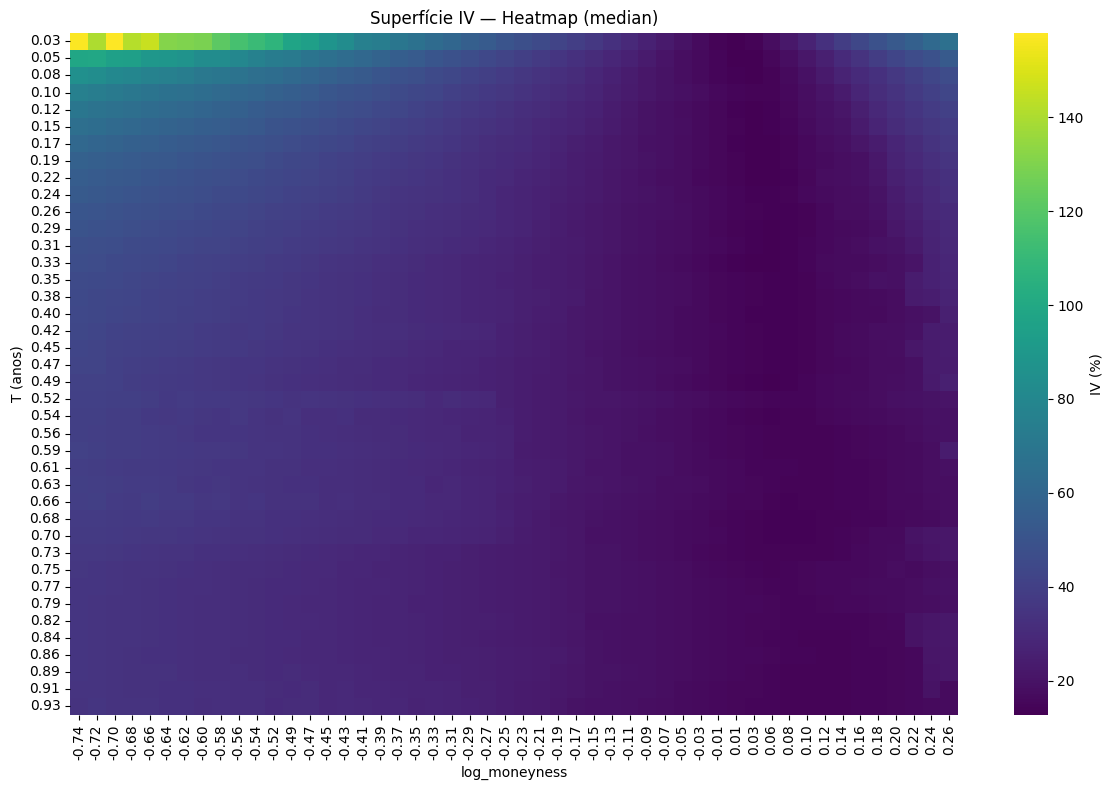

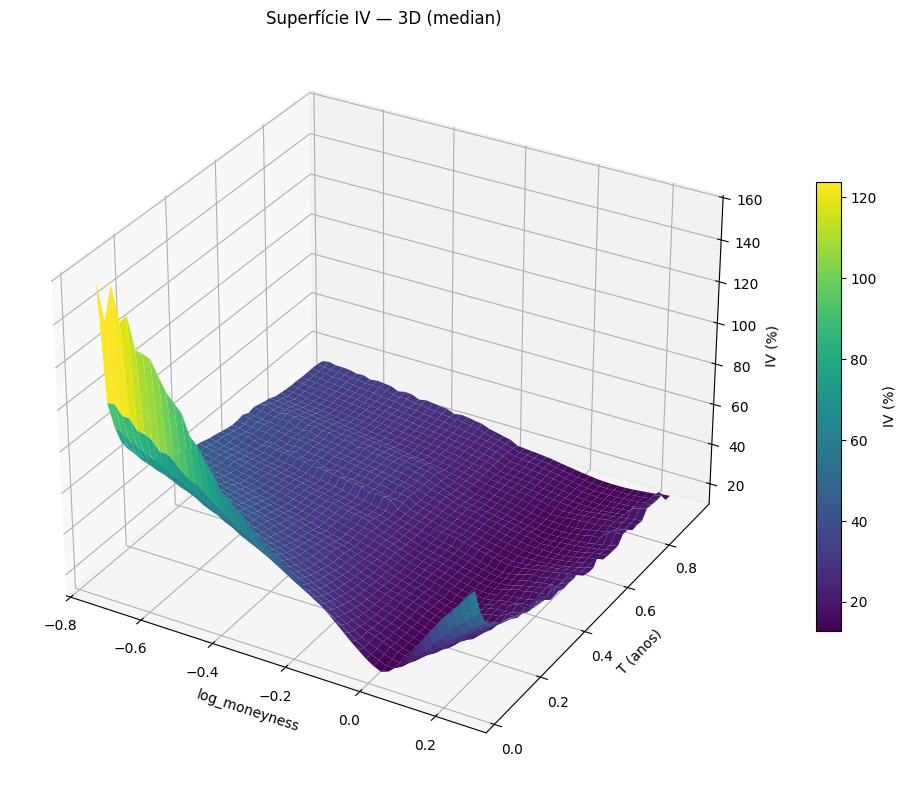

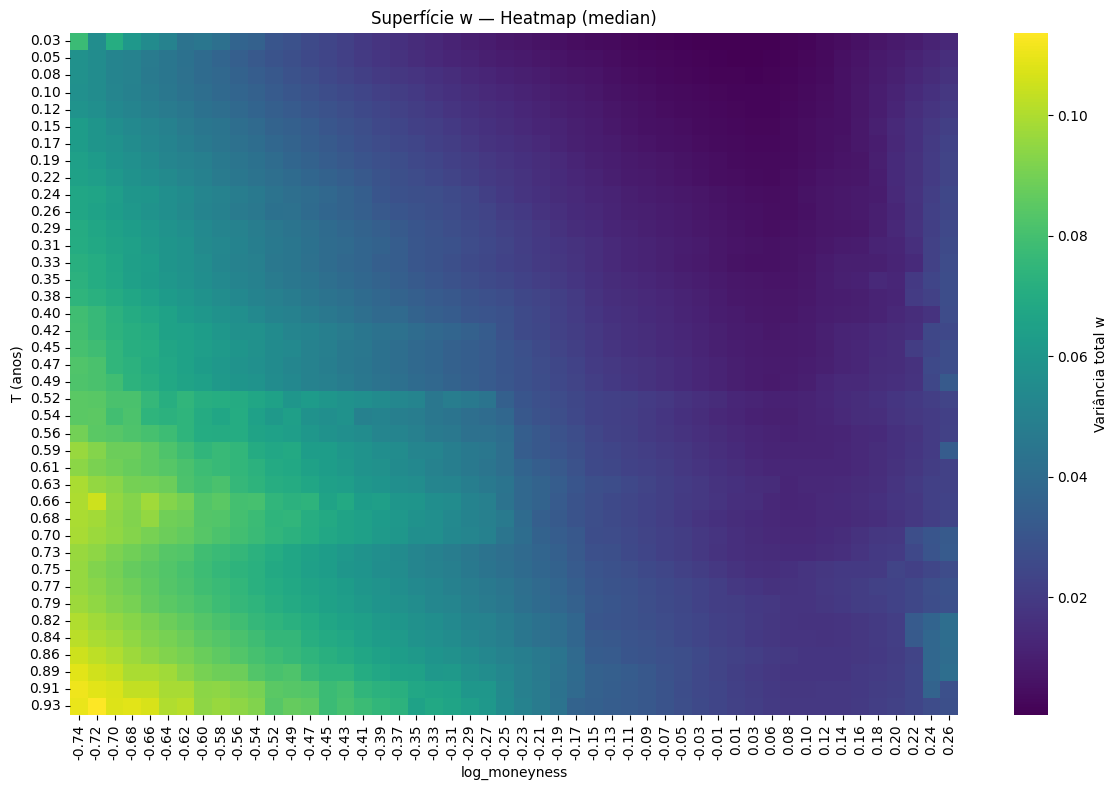

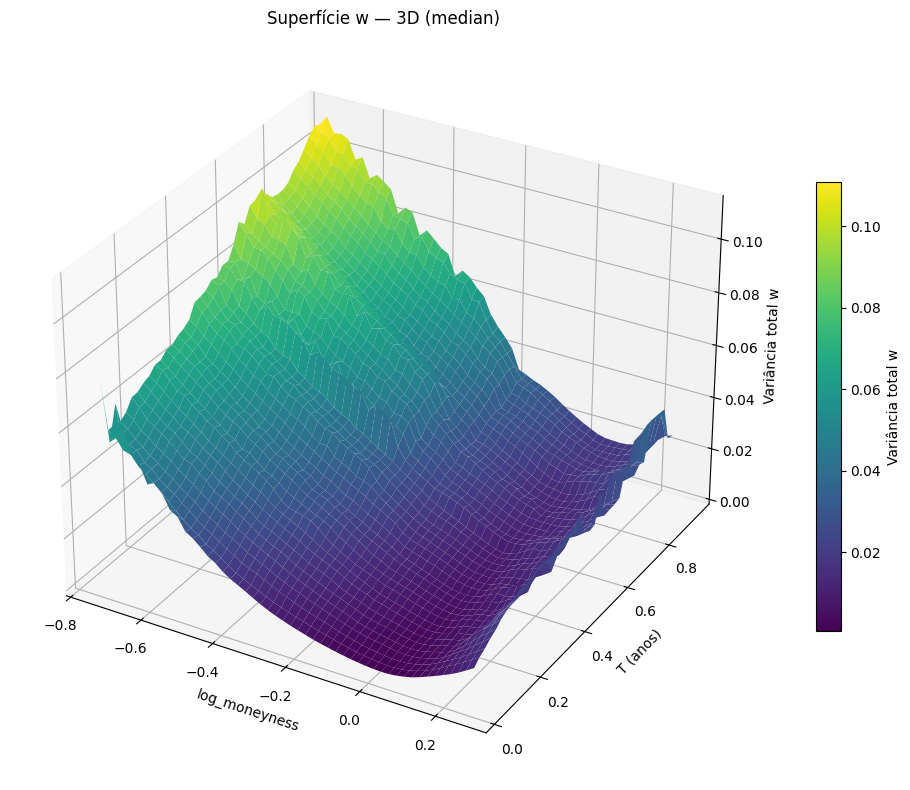

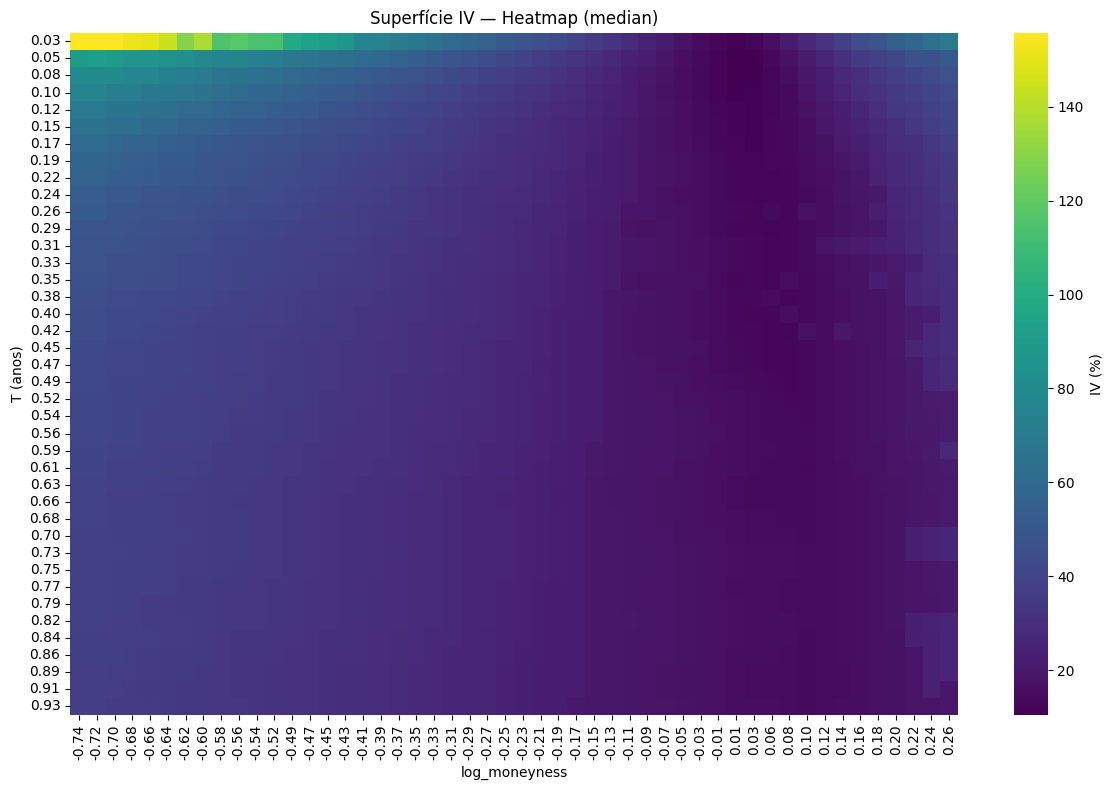

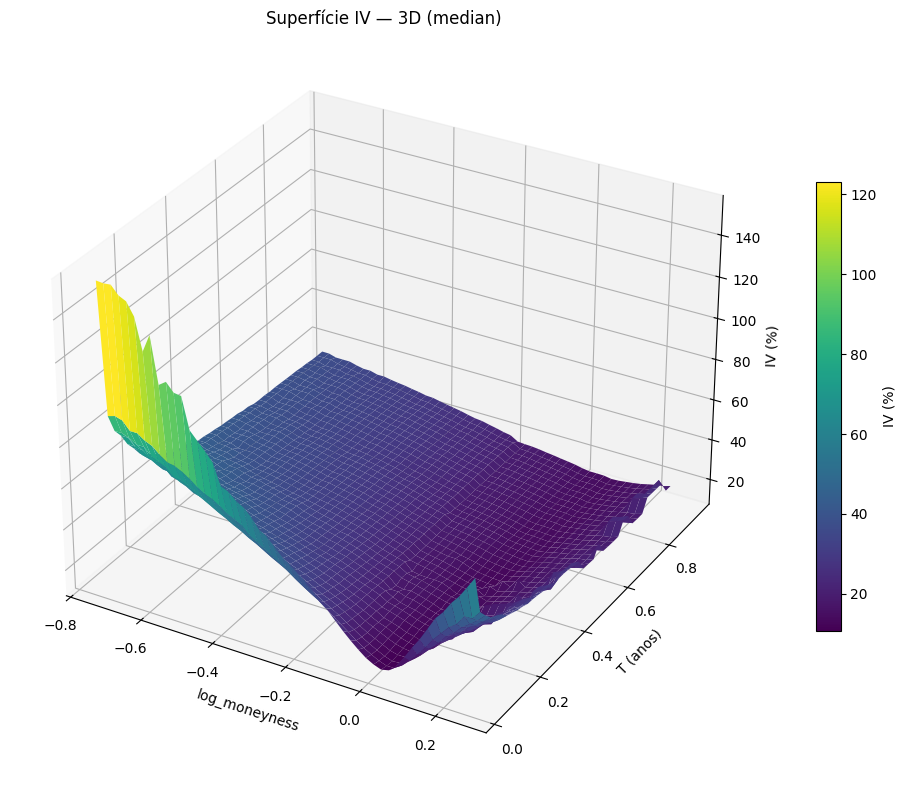

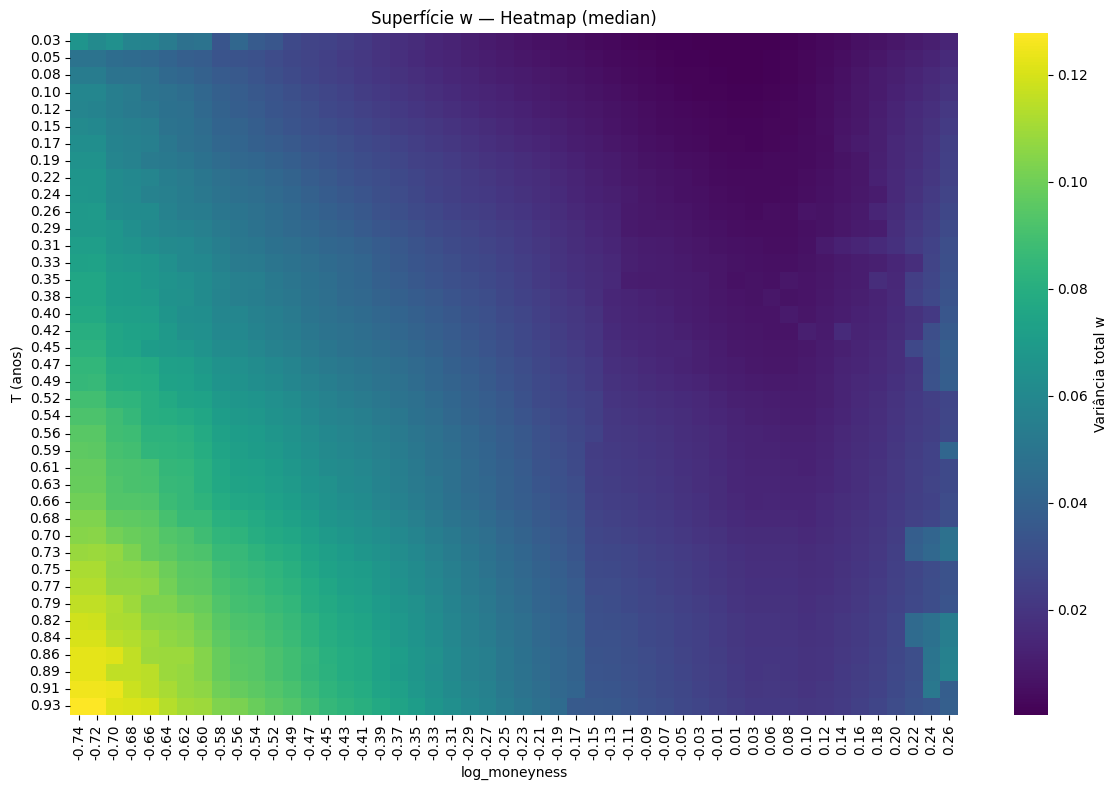

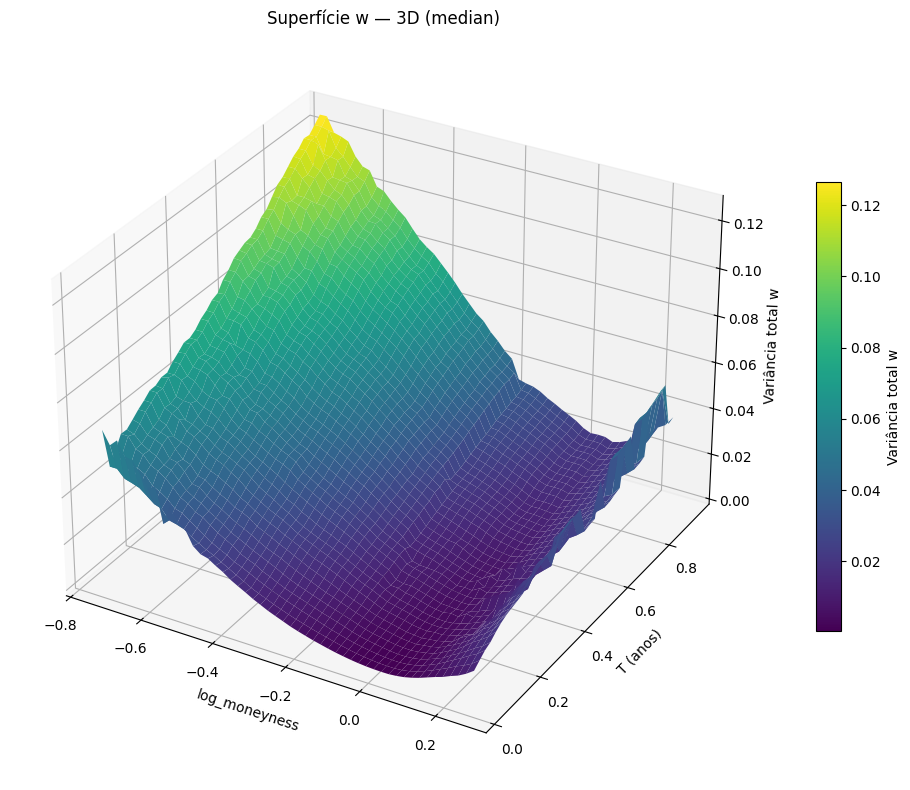

In [98]:
# 1) Superfície teórica
plot_ivs_and_variance_surfaces(
    df_test_puro_pred,
    x_col="log_moneyness", y_col="T", z_col="iv_teorica",
    agg="median",
    nbins_x=50, nbins_y=40,
    save_dir=DIR_GRAFICOS, filename_prefix="XGBoost"
)

# 2) Superfície de volatilidade implícita do modelo (não calibrada)
plot_ivs_and_variance_surfaces(
    df_test_puro_pred,
    x_col="log_moneyness", y_col="T", z_col="ivs_modelo",
    agg="median",
    nbins_x=50, nbins_y=40,
    save_dir=DIR_GRAFICOS, filename_prefix="XGBoost"
)

# # 3) Superfície de volatilidade implícita do modelo (calibrada)
# plot_ivs_and_variance_surfaces(
#     df_test_puro_pred_cal,
#     x_col="log_moneyness", y_col="T", z_col="ivs_modelo",
#     agg="median",
#     nbins_x=50, nbins_y=40,
#     save_dir=DIR_GRAFICOS, filename_prefix="XGBoost"
# )